# ST1519 Agile MLOps CA1 — PBI 02: MLP Neural Network Fraud Model

**Runs:** `MLP_safe` (production-eligible) and `MLP_full` (exploratory leakage check)

## 1. Model Objective

Predict whether an SP-buy order is **fraud** (`is_fraud = 1`) using information available when the order is assessed,
with **precise** flags for the Trust & Safety team and reasonable **recall**. The MLP is compared with the Decision Tree
(`notebooks/decision_tree_emi.ipynb`) and also used to check the 10 uncertain customer-snapshot features for leakage.

## 2. Algorithm Explanation and Justification

A **Multi-Layer Perceptron (MLP)** is a feed-forward neural network:

```
31 inputs  ->  64 neurons  ->  32 neurons  ->  1 output (fraud probability)
```

Each neuron computes a weighted sum of its inputs and passes it through an **activation function** (ReLU or tanh), which lets the network learn curved, non-linear patterns.
Training repeatedly shows batches of 1,024 orders and adjusts the weights with the **Adam** optimiser to reduce the log-loss. One pass over all training orders is one **epoch**.

**Why an MLP?**

- It is a **fundamentally different approach** from the Decision Tree. It learns smooth combinations of all features instead of yes/no rules.
- It can model complex interactions between features.
- It is available in scikit-learn (`MLPClassifier`), so no TensorFlow or PyTorch is needed.

**Model-specific decisions**

| Issue | Decision |
|---|---|
| Neural networks are sensitive to feature scale | `StandardScaler` fitted on **train only**, saved with the network in one `Pipeline` |
| `early_stopping=True` takes a **random** 10% validation sample (mixes dates) | Our own loop: train 1 epoch at a time with `partial_fit`, check the team's **chronological** validation set, keep the best epoch |
| No `class_weight` option | scikit-learn 1.7.2 supports `sample_weight`, so we tested `"balanced"` weights computed from **train** labels |
| No built-in feature importance (weights are not importances) | **Permutation importance** on validation data |

## 3. Imports and Configuration

Training logic lives in `src/mlp_model.py` and `src/model_utils.py`. PBI 05 can run it without this notebook:

```powershell
python src/mlp_model.py                # trains MLP_safe + MLP_full and logs to MLflow
```

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

# Find the repository root so "src/" can be imported (works from notebooks/ or the root)
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data_split.py").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import model_utils as mu                       # shared loading / evaluation / MLflow helpers
import mlp_model as mlp                     # this notebook's model
from data_processing import SNAPSHOT_FEATURES  # team's list of 10 uncertain snapshot features
from data_split import create_split_labels      # team's shared chronological split

# ---- Configuration (no personal paths or secrets in code) ----
DATA_DIR = os.environ.get("FRAUD_DATA_DIR", REPO_ROOT / "data" / "processed")
OUTPUT_DIR = REPO_ROOT / "outputs"     # local plots/models (not committed)
RUN_SEARCH = True                      # False = skip the search and use the saved settings
LOG_TO_MLFLOW = True                   # uses $MLFLOW_TRACKING_URI, else a LOCAL mlruns/ store
DEVELOPER = mu.DEFAULT_DEVELOPER     # "emi" unless $MODEL_DEVELOPER is set

pd.set_option("display.float_format", "{:.4f}".format)
print("Repository:", REPO_ROOT)
print("Random seed:", mu.RANDOM_SEED)

Repository: /srv/MLOps_CA1_group5
Random seed: 42


## 4. Dataset Loading and Validation

Load both processed feature files from PBI 01 and check that:

- the required columns exist and `is_fraud` only contains 0 and 1
- there are no duplicate orders (`country_code` + `order_id` is the order key)
- no feature has missing or infinite values
- both files contain **exactly the same orders and labels, in the same order**

The SHA-256 checksum identifies the exact file version, so every teammate can confirm they used the same data.

In [2]:
safe_path = mu.dataset_path("safe", DATA_DIR)
full_path = mu.dataset_path("full", DATA_DIR)

df_safe = mu.load_feature_data(safe_path)   # raises an error if any check fails
df_full = mu.load_feature_data(full_path)
mu.check_same_orders(df_safe, df_full)

checksums = {"safe": mu.file_sha256(safe_path), "full": mu.file_sha256(full_path)}
pd.DataFrame({
    "rows": [len(df_safe), len(df_full)],
    "columns": [df_safe.shape[1], df_full.shape[1]],
    "features": [len(mu.get_feature_columns(df_safe)), len(mu.get_feature_columns(df_full))],
    "fraud_rate_%": [df_safe["is_fraud"].mean() * 100, df_full["is_fraud"].mean() * 100],
    "sha256": [checksums["safe"], checksums["full"]],
}, index=["safe", "full"])

,rows,columns,features,fraud_rate_%,sha256
safe,949872,36,31,10.9933,656a05ca11891816989d51eeaf4c706aab2e9b38682fdf...
full,949872,46,41,10.9933,d5abc1ac0ce107b1118a47327965b2ba1393f917a59b4f...


## 5. Feature Selection

- **Not used as inputs:** `country_code`, `order_id`, `customer_id`, `order_date` (kept for tracking and splitting) and the target `is_fraud`.
  Country is still used, through the one-hot columns `country_code_BD`, `country_code_MY`, and so on.
- **`refund_value` is never a feature.** Every fraud order has a refund of 0, so the refund is recorded *after* the fraud decision (target leakage).
- The **full** dataset has 10 extra customer-snapshot features. The customer table seems to be one snapshot taken near the end of the data (around 11 May 2023), so these values may include activity that happened **after** an order was placed.

In [3]:
safe_features = mu.get_feature_columns(df_safe)   # also checks no forbidden column is a feature
full_features = mu.get_feature_columns(df_full)
extra_features = [f for f in full_features if f not in safe_features]

print("Safe features:", len(safe_features))
print("Full features:", len(full_features))
print("Extra features in full = SNAPSHOT_FEATURES:", sorted(extra_features) == sorted(SNAPSHOT_FEATURES))
print("refund_value in either dataset:", "refund_value" in df_safe.columns or "refund_value" in df_full.columns)
print("\nExtra (snapshot) features:", extra_features)

Safe features: 31
Full features: 41
Extra features in full = SNAPSHOT_FEATURES: True
refund_value in either dataset: False

Extra (snapshot) features: ['cancel_rate', 'refund_rate', 'avg_payment_per_order', 'mobile_verified', 'associated_capped', 'log_num_orders_last_50days', 'log_num_cancelled_orders_last_50days', 'log_num_refund_orders_last_50days', 'log_total_payment_last_50days', 'log_num_associated_customers']


## 6. Shared Chronological Split

We reuse `create_split_labels()` from `src/data_split.py`, so every teammate and both datasets use **the same orders**:

- **Train:** up to 15 Mar 2023, used to fit the model
- **Validation:** 16 Mar to 13 Apr 2023, used to choose hyperparameters and the decision threshold
- **Test:** from 14 Apr 2023, used only once for the final scores

The split is by date, not random, because the model will be used on *future* orders.
A random split would let the model learn from orders that happen after the ones it is tested on.

In [4]:
split = create_split_labels(df_safe)
assert split.equals(create_split_labels(df_full)), "Safe and full splits differ!"

split_summary = (df_safe.assign(split=split)
                 .groupby("split")
                 .agg(first_date=("order_date", "min"), last_date=("order_date", "max"),
                      orders=("is_fraud", "size"), fraud_orders=("is_fraud", "sum"),
                      fraud_rate=("is_fraud", "mean"))
                 .loc[["Train", "Validation", "Test"]])
split_summary["share_%"] = split_summary["orders"] / len(df_safe) * 100
split_summary

,first_date,last_date,orders,fraud_orders,fraud_rate,share_%
split,,,,,,
Train,2022-11-12,2023-03-15,665876,67594,0.1015,70.1017
Validation,2023-03-16,2023-04-13,139874,18993,0.1358,14.7256
Test,2023-04-14,2023-05-11,144122,17835,0.1237,15.1728


## 7. Class Imbalance Analysis

Only about 1 in 9 orders is fraud. A model that always predicts "not fraud" would score about 89% accuracy while catching **no** fraud.
That is why we focus on **precision, recall, F1 and average precision** for the fraud class, not on accuracy.

The fraud rate is also **higher in later periods** (10.2% in train, 13.6% in validation, 12.4% in test), so the data changes over time.

In [5]:
for name in ["Train", "Validation", "Test"]:
    y = df_safe.loc[split == name, "is_fraud"]
    print(f"{name:<11} not fraud: {(y == 0).sum():>7,}   fraud: {(y == 1).sum():>6,}   "
          f"fraud %: {y.mean() * 100:5.2f}   ratio: {(y == 0).sum() / (y == 1).sum():.1f} : 1")

Train       not fraud: 598,282   fraud: 67,594   fraud %: 10.15   ratio: 8.9 : 1
Validation  not fraud: 120,881   fraud: 18,993   fraud %: 13.58   ratio: 6.4 : 1
Test        not fraud: 126,287   fraud: 17,835   fraud %: 12.37   ratio: 7.1 : 1


## 8. Hyperparameter Selection

Each candidate changes **one idea** from the suggested starting point
(`hidden_layer_sizes=(64, 32)`, `relu`, `adam`, `alpha=0.0001`, `batch_size=1024`, `learning_rate_init=0.001`, `max_iter=50`, `random_state=42`).
Every candidate is trained on **safe Train**, with early stopping on **safe Validation** (patience 5 epochs, `tol=0.0001` AP), and is ranked by validation average precision.

**Round 1:** starting point, `class_weight="balanced"`, a smaller network (32, 16), a bigger network (128, 64), stronger `alpha`, and `tanh` activation.

**Round 2 (added after diagnosing round 1):** most ReLU networks reached their best validation AP after **only 1 epoch** and then got worse.
They learned patterns from the training period that did not carry over to the later validation period.
So we tried a **10× smaller learning rate** with ReLU, and `tanh` with stronger regularisation.

The full search takes about 3–4 minutes.

In [6]:
if RUN_SEARCH:
    tuning_table, params = mlp.tune(df_safe)
    if LOG_TO_MLFLOW:
        mu.log_tuning_table(tuning_table, "mlp_tuning", developer=DEVELOPER)
    display(tuning_table)
else:
    params = mlp.SELECTED_PARAMS

print("Selected hyperparameters:", params)
print("Same as SELECTED_PARAMS saved in src/mlp_model.py:", params == mlp.SELECTED_PARAMS)

  {'activation': 'relu'}: val AP 0.4821 in 8s


  {'activation': 'relu', 'class_weight': 'balanced'}: val AP 0.4929 in 8s


  {'activation': 'relu', 'hidden_layer_sizes': (32, 16)}: val AP 0.4946 in 19s


  {'activation': 'relu', 'hidden_layer_sizes': (128, 64)}: val AP 0.4969 in 13s


  {'activation': 'relu', 'alpha': 0.001}: val AP 0.4815 in 8s


  {'activation': 'tanh'}: val AP 0.5098 in 32s


  {'activation': 'relu', 'learning_rate_init': 0.0001}: val AP 0.4989 in 63s


  {'activation': 'tanh', 'alpha': 0.001}: val AP 0.5022 in 16s


[MLflow] No shared server configured -> LOCAL testing store: sqlite:////srv/MLOps_CA1_group5/mlruns/mlflow.db


,change,hidden_layer_sizes,activation,alpha,class_weight,val_average_precision,val_roc_auc,epochs_run,best_epoch,train_seconds
0,{'activation': 'tanh'},"(64, 32)",tanh,0.0001,None,0.5098,0.8518,33,28,32.0000
1,"{'activation': 'tanh', 'alpha': 0.001}","(64, 32)",tanh,0.0010,None,0.5022,0.8498,16,11,16.2000
2,"{'activation': 'relu', 'learning_rate_init': 0...","(64, 32)",relu,0.0001,None,0.4989,0.8142,50,49,63.3000
3,"{'activation': 'relu', 'hidden_layer_sizes': (...","(128, 64)",relu,0.0001,None,0.4969,0.8115,6,1,13.3000
4,"{'activation': 'relu', 'hidden_layer_sizes': (...","(32, 16)",relu,0.0001,None,0.4946,0.8161,23,18,19.3000
5,"{'activation': 'relu', 'class_weight': 'balanc...","(64, 32)",relu,0.0001,balanced,0.4929,0.8124,6,1,7.7000
6,{'activation': 'relu'},"(64, 32)",relu,0.0001,None,0.4821,0.8080,6,1,7.9000
7,"{'activation': 'relu', 'alpha': 0.001}","(64, 32)",relu,0.0010,None,0.4815,0.8080,6,1,7.9000


Selected hyperparameters: {'hidden_layer_sizes': (64, 32), 'activation': 'tanh', 'solver': 'adam', 'alpha': 0.0001, 'batch_size': 1024, 'learning_rate_init': 0.001, 'max_iter': 50, 'n_iter_no_change': 5, 'tol': 0.0001, 'class_weight': None, 'random_state': 42}
Same as SELECTED_PARAMS saved in src/mlp_model.py: True


**Reading the search results**

- **tanh** gave the best validation AP. It improved steadily for about 28 epochs, while most ReLU networks peaked at epoch 1.
- The smaller learning rate fixed the ReLU "epoch 1" problem (it kept improving for about 50 epochs), but it scored lower and took about twice as long.
- `class_weight="balanced"` helped ReLU slightly but did not beat tanh. As with the tree, the decision threshold already handles the imbalance.
- Bigger is not better here: (128, 64) did not beat the tanh (64, 32) network.

## 9. Safe Dataset Training (MLP_safe)

`mu.run_training()` does the same steps for every run:

1. Split with the shared chronological function.
2. Train on **Train** only.
3. Choose the decision threshold that gives the best fraud F1 on **Validation**.
4. Score **Test** once with that threshold.
5. Save plots and the model locally, and log everything to MLflow.

`MLP_safe` is the **production-eligible** run.

In [7]:
mlflow_location = mu.setup_mlflow() if LOG_TO_MLFLOW else None
common = dict(output_dir=OUTPUT_DIR, mlflow_location=mlflow_location, developer=DEVELOPER,
              snapshot_features=SNAPSHOT_FEATURES, trusted_types=mlp.TRUSTED_TYPES)

result_safe, model_safe = mu.run_training(
    mlp.ALGORITHM, mlp.SHORT_NAME, "safe", df_safe, mlp.train_model, params,
    mlp.feature_importance, dataset_sha256=checksums["safe"], **common)

print(f"Threshold chosen on validation: {result_safe['threshold']:.4f}")
print(f"Training time: {result_safe['train_seconds']:.1f} s")
print("Extra training info:", result_safe["extra_metrics"])

[MLflow] No shared server configured -> LOCAL testing store: sqlite:////srv/MLOps_CA1_group5/mlruns/mlflow.db


2026/11/25 10:55:18 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Threshold chosen on validation: 0.1412
Training time: 32.1 s
Extra training info: {'epochs_run': 33.0, 'best_epoch': 28.0, 'best_validation_average_precision_during_training': 0.5098139191188616, 'final_train_loss': 0.2565677732378604, 'stopped_early': 1.0, 'n_weights': 4161.0}


## 10. Full Dataset Training (MLP_full)

Same hyperparameters, seed, split, preprocessing **and the same threshold** as `MLP_safe`.
The **only** difference is the 10 extra snapshot features, so any change in results comes from them.

This run is tagged `exploratory=true` and `production_eligible=false` in MLflow. It must never be registered or promoted.

In [8]:
result_full, model_full = mu.run_training(
    mlp.ALGORITHM, mlp.SHORT_NAME, "full", df_full, mlp.train_model, params,
    mlp.feature_importance, threshold=result_safe["threshold"],   # reuse the safe threshold
    dataset_sha256=checksums["full"], **common)

print(f"Threshold reused: {result_full['threshold']:.4f}")
print(f"Training time: {result_full['train_seconds']:.1f} s")

2026/11/25 10:55:31 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Threshold reused: 0.1412
Training time: 6.4 s


## 11. Model Evaluation

Results on the **test** period (14 Apr to 11 May 2023), which was not used for any decision.

- **Precision:** of the orders we flag, how many are really fraud (analysts' time is not wasted)
- **Recall:** of all fraud orders, how many we catch
- **Average precision (AP):** summarises the whole precision-recall curve without needing a threshold.
  A random model would score about equal to the fraud rate (about 0.12 here).

In [9]:
results = [result_safe, result_full]
comparison = mu.comparison_table(results)
comparison

,MLP_safe,MLP_full
Accuracy,0.8106,0.8002
Precision (fraud),0.3593,0.3577
Recall (fraud),0.6773,0.7726
F1 (fraud),0.4695,0.4890
Average precision,0.3995,0.4259
ROC-AUC,0.8112,0.8557
TP,12079,13779
FP,21536,24746
FN,5756,4056
TN,104751,101541


MLP_safe


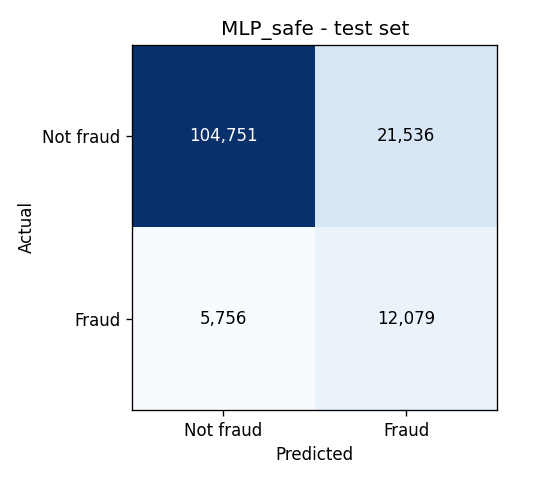

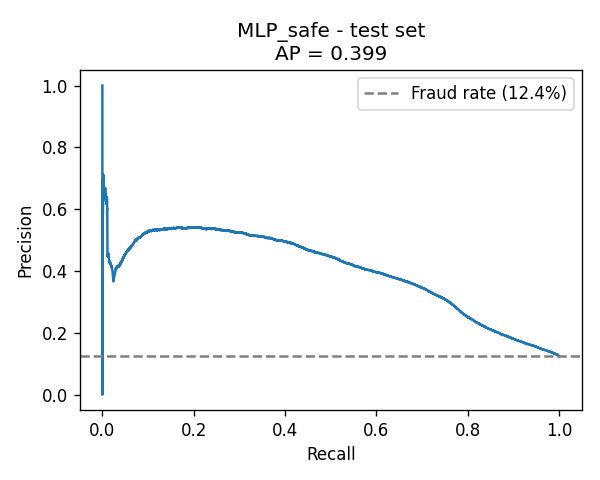

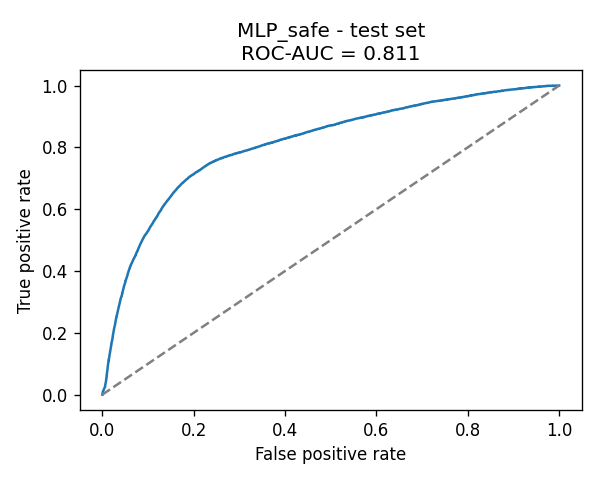

MLP_full


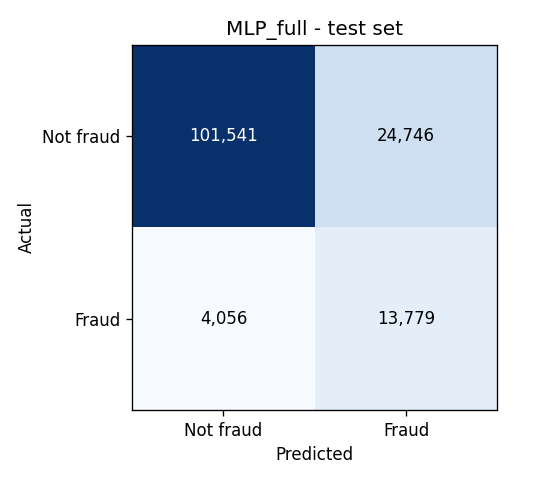

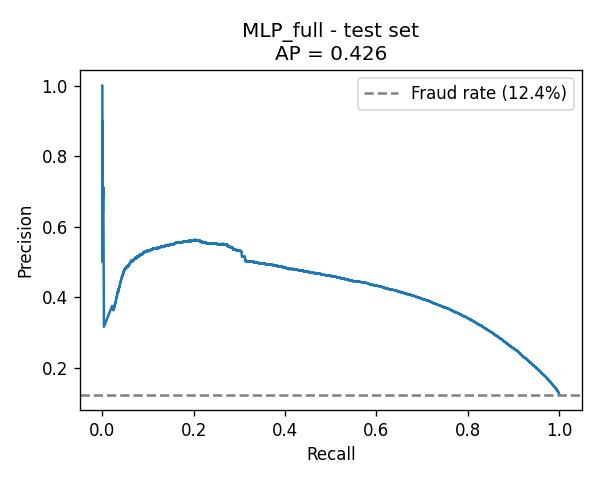

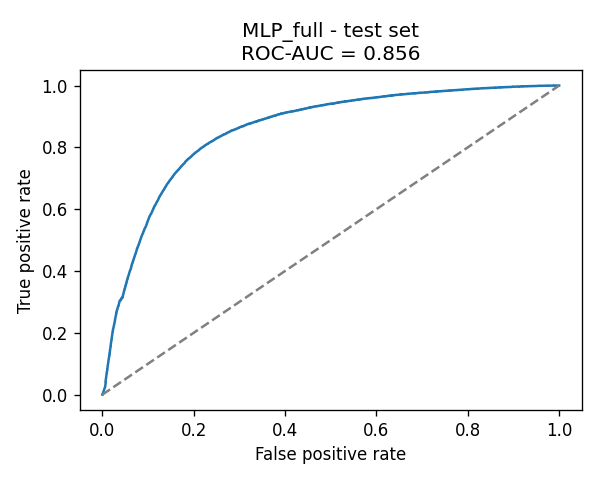

In [10]:
for run in ["MLP_safe", "MLP_full"]:
    plots = OUTPUT_DIR / run / "plots"
    print(run)
    display(Image(plots / "confusion_matrix_test.png"), Image(plots / "precision_recall_test.png"),
            Image(plots / "roc_test.png"))

## 12. Safe versus Full Comparison

In [11]:
metrics = ["Precision (fraud)", "Recall (fraud)", "F1 (fraud)", "Average precision", "ROC-AUC", "Train seconds"]
diff = comparison.loc[metrics].T.astype(float).T
diff["full - safe"] = diff.iloc[:, 1] - diff.iloc[:, 0]
diff["validation AP (safe / full)"] = [""] * len(diff)
diff.loc["Average precision", "validation AP (safe / full)"] = (
    f"{result_safe['validation']['average_precision']:.4f} / {result_full['validation']['average_precision']:.4f}")
display(diff)

ax = comparison.loc[metrics[:-1]].astype(float).plot.bar(figsize=(8, 4), rot=0)
ax.set_title("Test-set metrics: safe vs full features")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

,MLP_safe,MLP_full,full - safe,validation AP (safe / full)
Precision (fraud),0.3593,0.3577,-0.0017,
Recall (fraud),0.6773,0.7726,0.0953,
F1 (fraud),0.4695,0.4890,0.0194,
Average precision,0.3995,0.4259,0.0264,0.5098 / 0.5222
ROC-AUC,0.8112,0.8557,0.0445,
Train seconds,32.0786,6.3563,-25.7223,


## 13. Potential Data Leakage Analysis

A higher score with the full features does **not** prove leakage. Those features might simply be useful.
A more informative check is to look at **when** the extra features help.

If the customer snapshot was taken around 11 May 2023, its "last 50 days" window covers about 22 March to 11 May.
For orders in that window, the snapshot may already count the order itself and what happened afterwards.
If the snapshot features leak, their advantage should **grow for orders closer to the snapshot date**.

The table uses only months the models never trained on (after 15 March).

In [12]:
by_month = mu.gain_by_month(model_safe, model_full, df_safe, df_full)
display(by_month)

ax = by_month.plot(x="month", y="gain_full_minus_safe", kind="bar", legend=False, rot=0, figsize=(6, 3.5))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("AP gain (full - safe)")
ax.set_title("Extra benefit of snapshot features by month")
plt.tight_layout()
plt.show()

,month,orders,fraud_rate_%,safe_AP,full_AP,gain_full_minus_safe
0,2023-03,77691,13.9400,0.5376,0.5324,-0.0052
1,2023-04,148855,12.6100,0.4253,0.4459,0.0206
2,2023-05,57450,12.5700,0.4264,0.4599,0.0335


**Interpretation (values from the run in this notebook)**

| Month (unseen) | MLP gain from snapshot features |
|---|---|
| March (16th to 31st) | about −0.005 (no benefit) |
| April | about +0.021 |
| May (1st to 11th) | about +0.033 |

This is the same pattern as the Decision Tree: **no benefit for the earliest unseen orders, and a growing benefit towards the presumed snapshot date.**
It is consistent with temporal leakage but **not proof**, because the fraud pattern also drifts over time.
Two different algorithms showing the same pattern makes it more convincing. The snapshot features stay **excluded from production**.

## Convergence Analysis

The training loss should go down. Validation AP shows when the network stops improving on **unseen, later** orders (the dashed line marks the best epoch, which is kept).

MLP_safe: epochs run 33, best epoch 28, final training loss 0.2566, weights 4161


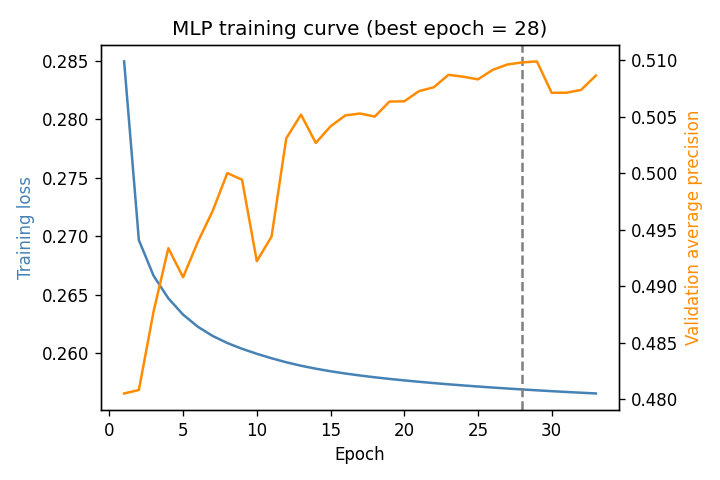

MLP_full: epochs run 6, best epoch 1, final training loss 0.2002, weights 4801


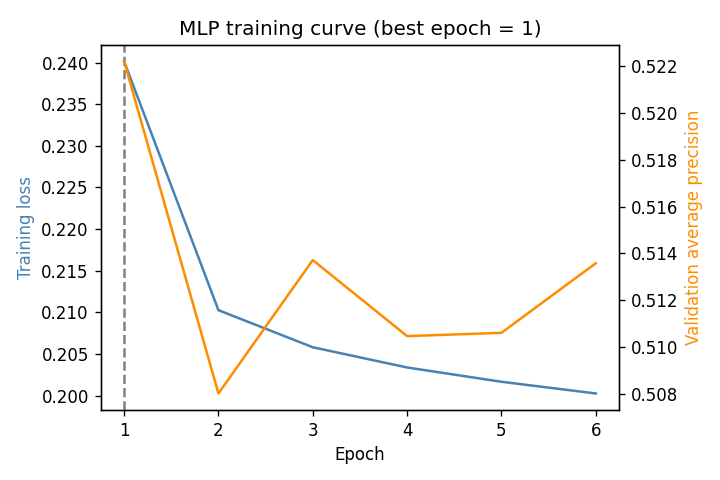

In [13]:
for run, res in [("MLP_safe", result_safe), ("MLP_full", result_full)]:
    m = res["extra_metrics"]
    print(f"{run}: epochs run {m['epochs_run']:.0f}, best epoch {m['best_epoch']:.0f}, "
          f"final training loss {m['final_train_loss']:.4f}, weights {m['n_weights']:.0f}")
    display(Image(OUTPUT_DIR / run / "plots" / "training_curve.png"))

**Reading the curves:** MLP_safe improves on validation for many epochs before stopping.
MLP_full reaches its best validation AP almost immediately and then declines while its training loss keeps falling, which is classic overfitting.
The snapshot features make the training data easier to fit, but that fit does not carry over as well to later periods.

## 14. Feature Importance (Permutation)

We shuffle one feature at a time in 20,000 validation orders (3 repeats) and measure how much **average precision drops**.
A large drop means the model relies on that feature. Red bars are snapshot features.

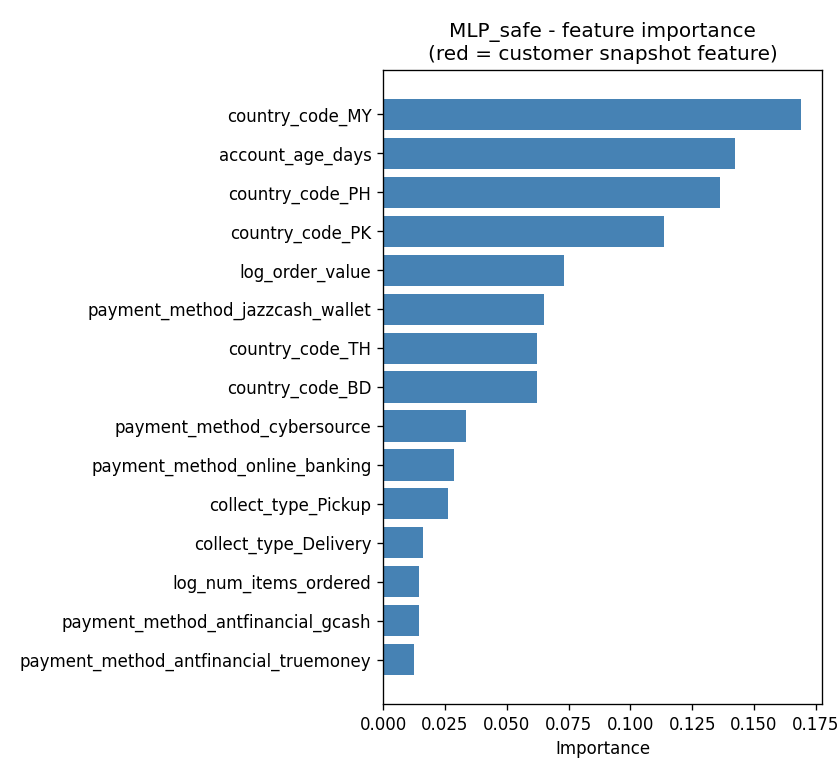

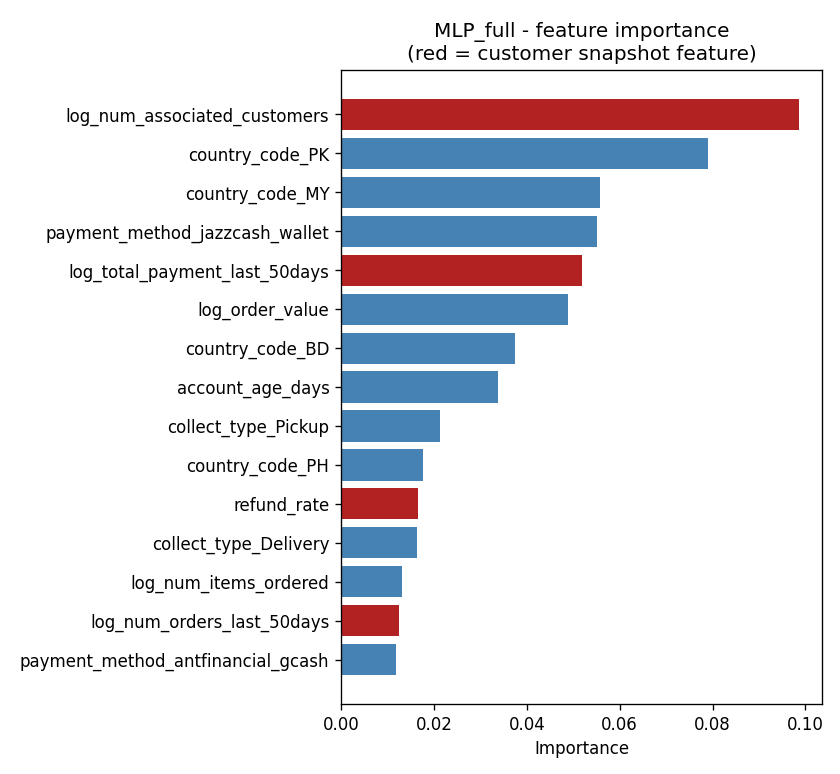

Share of MLP_full (positive) permutation importance from snapshot features: 31.9%


In [14]:
for run in ["MLP_safe", "MLP_full"]:
    display(Image(OUTPUT_DIR / run / "plots" / "feature_importance.png"))

imp = result_full["importance"]
positive = imp["importance"].clip(lower=0)
share = positive[imp["feature"].isin(SNAPSHOT_FEATURES)].sum() / positive.sum()
print(f"Share of MLP_full (positive) permutation importance from snapshot features: {share:.1%}")

## 15. MLflow Experiment Tracking

Logging uses the team's shared **`src/mlflow_utils.py`** (#38): `start_model_run`, `log_model_parameters`,
`log_classification_metrics`, `log_evaluation_artifacts` and `log_trained_model`. Experiment **`SP-buy-Fraud-Detection`**,
run names **`{member}_{algorithm}_{dataset_version}_{model_version}`** (e.g. `emi_decision_tree_safe_v1`, `emi_mlp_full_v1`),
and metric names `val_*` / `test_*` (`pr_auc` = average precision).

Each run logs:

- **Tags:** `team_member`, `algorithm`, `dataset_version`, `model_version`, `production_eligible`, `exploratory`, `tracking_location`
- **Parameters:** hyperparameters, seed, dataset SHA-256, feature count, train/validation/test row counts, `decision_threshold`
- **Metrics:** validation and test metrics, TP/TN/FP/FN, training and inference time
- **Artifacts:** confusion matrix, PR and ROC curves, feature importance (plot and CSV), feature list, and the model with its signature (via `log_trained_model`)

The tracking URI is read from the `MLFLOW_TRACKING_URI` environment variable, so no server address is hardcoded.
If it is not set, runs go to a **local** test store (`mlruns/`, git-ignored), tagged `tracking_location=local`.
To view local runs, run `mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db` from the repository root.

In [15]:
for r in results:
    print(f"{mu.mlflow_run_name(r):<28} run_id={r.get('mlflow_run_id', 'not logged')}  "
          f"production_eligible={r['production_eligible']}  location={mlflow_location}")

emi_mlp_safe_v1              run_id=977a6492e60f48feb6a85dab470f45d0  production_eligible=True  location=local
emi_mlp_full_v1              run_id=5c7abf4934a94196bd65f83f76717cfa  production_eligible=False  location=local


## Comparison with the Decision Tree (safe models only)

This loads the Decision Tree results saved by `notebooks/decision_tree_emi.ipynb` (or by `python src/decision_tree.py`), if they exist.

In [16]:
dt_file = OUTPUT_DIR / "DT_safe" / "result.json"
if dt_file.exists():
    import json
    dt_safe = json.loads(dt_file.read_text())
    for k in ("train_seconds", "inference_seconds_test", "threshold"):
        dt_safe[k] = float(dt_safe[k])
    dt_safe["production_eligible"] = True
    display(mu.comparison_table([dt_safe, result_safe]))
    print("Validation AP - DT_safe:", round(dt_safe["validation"]["average_precision"], 4),
          "| MLP_safe:", round(result_safe["validation"]["average_precision"], 4))
else:
    print("Run notebooks/decision_tree_emi.ipynb first to compare.")

,DT_safe,MLP_safe
Accuracy,0.8056,0.8106
Precision (fraud),0.3524,0.3593
Recall (fraud),0.6821,0.6773
F1 (fraud),0.4648,0.4695
Average precision,0.4173,0.3995
ROC-AUC,0.8031,0.8112
TP,12166,12079
FP,22354,21536
FN,5669,5756
TN,103933,104751


Validation AP - DT_safe: 0.516 | MLP_safe: 0.5098


## 16. Conclusion and Limitations

**Results (test period 14 Apr to 11 May 2023, values from this notebook's run)**

| | MLP_safe | MLP_full | DT_safe (for reference) |
|---|---|---|---|
| Average precision | 0.399 | 0.426 | 0.417 |
| ROC-AUC | 0.811 | 0.856 | 0.803 |
| Fraud precision | 0.359 | 0.358 | 0.352 |
| Fraud recall | 0.677 | 0.773 | 0.682 |
| Fraud F1 | 0.470 | 0.489 | 0.465 |
| Training time | about 35 s | about 8 s (stopped early) | about 4–5 s |
| Production eligible | **Yes** | No | **Yes** |

**Conclusions**

- **MLP_safe and DT_safe perform very similarly.** The MLP has slightly better ROC-AUC, precision and F1, while the tree has better average precision on both validation (0.516 vs 0.510) and test (0.417 vs 0.399).
  The tree is also about 8× faster to train and much easier to explain. On these results, the extra complexity of the MLP is **not justified**.
  The team should still make the final choice using its agreed selection metric.
- Snapshot features give the MLP about +0.03 test AP, with the same growing-towards-snapshot-date pattern as the tree. MLP_full also overfits after 1 epoch.
  This supports (but does not prove) the leakage concern, and the full model stays exploratory only.
- MLP retraining takes about 35–40 s on 2 CPU cores. It fits the PBI 05 budget for one model, but together with ETL and the other models the full workflow must be timed end to end.

**Limitations**

- Only 8 configurations were tried, so a wider search might do better (at the cost of runtime).
- Results depend on the random weight initialisation (seed 42). Other seeds may differ slightly.
- Both models perform worse on the newer test period than on validation (drift). Regular retraining is needed.
- The F1-based threshold is a team decision to confirm (precision vs recall trade-off).